
# Assignments #2 Supervised Learning  and Unsupervised learning 

In [22]:
# ---- (Run this first) ----
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, Normalizer, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error, r2_score
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import Perceptron, LinearRegression
from sklearn import datasets
from sklearn.neighbors import NearestNeighbors

# letting plots appear inline
%matplotlib inline

print("All Done!") 


All Done!



## Task 1 Theory questions

Answer **in text** below each question. (1-3 lines per answer)

1. What is **supervised learning**? 
2. Define **classification**. Give one example.  
3. Define **regression**. Give one example.
4. Compare the **difference** between classification and regression? 
5. What is a **confusion matrix** used for and how does it help evaluate the performance of a classification model?
6. Why do we **preprocess** data before training? Name **two** techniques.

In [ ]:
#  -> (your answer):

# Supervised learning:
# Supervised learning is when the model is trained on labelled data, so every input has a known correct answer. 
# It learns the connection between input and label so it can predict on new data.

# Classification:
# Classification means putting data into a fixed number of categories. 
# Example: predicting if a person earns <=50K or >50K based on age, education and job.

# Regression:
# Regression estimates the relation between input and output, where the output is a continuous number. 
# Example: estimating house prices from attributes like number of rooms and location.

# Difference:
# Classification gives a discrete class label from a fixed set, while regression gives a continuous 
# value with infinite possible outputs. They also use different metrics, like accuracy and F1 for 
# classification and mean squared error for regression.

# Confusion Matrix:
# It is a table that compares the predicted labels against the actual labels on a test set. 
# It shows true positives, true negatives, false positives and false negatives, so you can see 
# which classes the model mixes up instead of only looking at accuracy. From it you can calculate accuracy, 
# precision, recall and F1.

# Preprocess:
# Raw data has different units and ranges, so a large feature can dominate just because of how it was measured. 
# Preprocessing puts the features on a common scale so the model trains better. Two techniques are mean removal, 
# which centres each feature on zero, and min max scaling, which scales values into the range 0 to 1.


## Task 2 Perceptron on a simple problem

We use **Perceptron** for a binary task (a "OR gate" data).

**Steps:**
0. Build small binary dataset `X_or`, `y_or`.
1. Train `Perceptron()` with default params.
2. Print predictions for all inputs.
3. Try different `max_iter` and `eta0` (learning rate).
4. Answer one question.

(Tip: Keep it simple. Focus on input → output mapping.)


In [25]:
# --- Task 2.0: Data (OR problem: output is 1 except when both inputs are 0)
X_or = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)
y_or = np.array([0,1,1,1])
# Exspektations = 0,1,1,1

# --- Task 2.1: Train Perceptron 
#     (Hint: use Perceptron() from sklearn.linear_model; then fit(X_or, y_or);
#            use default params first, then try changing max_iter and eta0)
print("Defalt: ")
model = Perceptron()
model.fit(X_or, y_or)

for x, y in zip(X_or, y_or):
    print(f"({x}, [{y}]) -> {model.predict([x])}")

print("\nMax_iter = 100 000 Eta0 = 0.01")
model2 = Perceptron(max_iter=100000, eta0=0.01)
model2.fit(X_or, y_or)
for x, y in zip(X_or, y_or):
    print(f"({x}, [{y}]) -> {model2.predict([x])}")

# --- Task 2.2: Predict
#      (Hint: use clf_perc.predict([x]) for each x in X_or, 
#             where clf_perc is the trained model, replace clf_perc with your model name)
print("\nMax_iter = 500 Eta0 = 0.1")
model3 = Perceptron(max_iter=500, eta0=0.1)
model3.fit(X_or, y_or)
for x, y in zip(X_or, y_or):
    print(f"({x}, [{y}]) -> {model3.predict([x])}")


# --- Task 2.3: Questions ---
# Q1: Change max_iter and/or eta0 and re-train. Do results change?
#  -> (your answer): It did not change the results

Defalt: 
([0. 0.], [0]) -> [0]
([0. 1.], [1]) -> [1]
([1. 0.], [1]) -> [1]
([1. 1.], [1]) -> [1]

Max_iter = 100 000 Eta0 = 0.01
([0. 0.], [0]) -> [0]
([0. 1.], [1]) -> [1]
([1. 0.], [1]) -> [1]
([1. 1.], [1]) -> [1]

Max_iter = 500 Eta0 = 0.1
([0. 0.], [0]) -> [0]
([0. 1.], [1]) -> [1]
([1. 0.], [1]) -> [1]
([1. 1.], [1]) -> [1]



## Task 3 Linear Regression (Single Variable)

We fit a **Linear Regression** model to a 1D dataset.

**Steps:**
1. Generate synthetic data: `y = 2.5 * x + noise`.
2. Fit `LinearRegression()`.
3. Report **MAE**, **MSE**, **R²**.
4. Plot data points and the regression line.
5. Answer questions 


MAE = 2.354638301330121
MSE = 9.454040949915617
r2 = 0.81891683989944



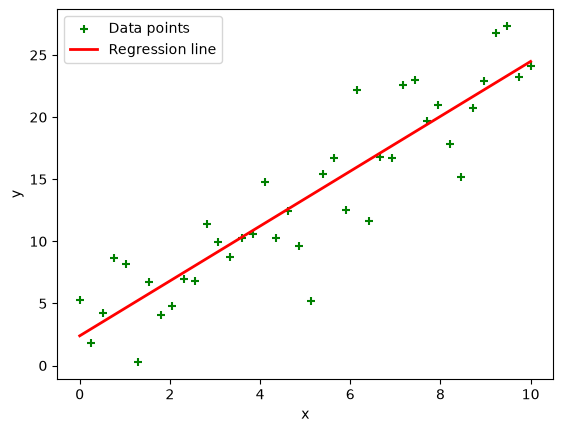

In [ ]:
# --- Task 3.1: Generate synthetic single variable data: y = 2.5 * x + noise, noise ~ N(0,1), X in [0,10], 40 samples
#     (Hint: use linspace to generate x values; use np.random.normal to generate noise)
np.random.seed(0)
x = np.linspace(0, 10, 40)
#noise = np.random.normal(0, 1, size = x.shape)
noise = np.random.normal(0, 3, size = x.shape)
y = 2.5 * x + noise
#y = 3 * x + noise
X = x.reshape(-1, 1)
#print(X)

# --- Task 3.2: Fit model 
#     (Hint: use LinearRegression() from sklearn.linear_model; then fit())
lin = LinearRegression()
lin.fit(X, y)
yPredict = lin.predict(X)
#print(yPredict)

# --- Task 3.3: Metrics (MAE, MSE, R²)
mae = mean_absolute_error(y, yPredict)
mse = mean_squared_error(y, yPredict)
r2 = r2_score(y, yPredict)
print(f"\nMAE = {mae}\nMSE = {mse}\nr2 = {r2}\n")

# --- Task 3.4: Plot data points and the regression line
plt.figure()
plt.scatter(x, y, color='green', marker='+', label='Data points')
plt.plot(x, yPredict, color='red', linewidth=2, label='Regression line')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

# --- Task 3.5: Questions ---
# Q1: Change the slope in data generation to 3.0 and re-run. What happens to R^2? 
#  -> (your answer): R2 increase slightly
# Q2: Try adding larger noise (e.g., std=3.0). How do MAE/MSE change?
#  -> (your answer): MAE and MSE both increase and R2 decreases



## (Final task) Task 4 End-to-End Classification Pipeline

We build a complete supervised learning pipeline using **Digits** data:
- **Aim:** Classify hand-written digits ("0"–"9").
- **Model:** `MLPClassifier`, a simple neural network.
- **Outputs:** Accuracy and **confusion matrix**.

**Steps:**
1. Load data: `datasets.load_digits()`.
2. Train/validation split: 80% / 20%.
3. Scale features with `StandardScaler()`.
4. Train `MLPClassifier(hidden_layer_sizes=(50,), max_iter=300, random_state=0)`.
5. Evaluate on validation set. Print accuracy.
6. Show the **confusion matrix** with `ConfusionMatrixDisplay`.
7. Write 3–5 lines: What mistakes are most common? Why?

**Tips:**
- If training warns about convergence, **increase** `max_iter`.
- Use a **small network** to keep runtime short.


Accuracy: 0.9777777777777777


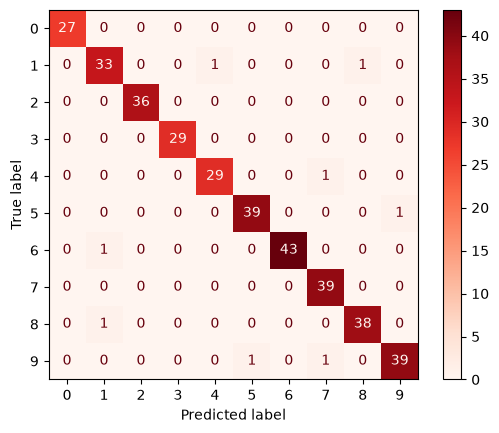

In [ ]:

# --- Task 4.1: Load digits
#     (Hint: use datasets.load_digits() from sklearn)
data = datasets.load_digits()
X, y = data.data, data.target

# --- Task 4.2: Split data into train and validation 
#     (Hint: use train_test_split from sklearn.model_selection)
X_t, X_val, y_t, y_val = train_test_split(X, y, test_size=0.20, random_state=0)
#X_t, X_val, y_t, y_val = train_test_split(X, y, test_size=0.10, random_state=42)
#X_t, X_val, y_t, y_val = train_test_split(X, y, test_size=0.30, random_state=1)

# --- Task 4.3: Scaling (NOTE: fit on training dataset only!!)
#     Important: fit the scaler on the training data ONLY (scaler.fit(X_train) or scaler.fit_transform(X_train)), 
#       which computes the mean/std (or min/max) from training alone. 
#       Then use the same scaler to transform the validation data (scaler.transform(X_val)).
#       Why?:  Because we want to avoid data leakage from the validation set into the training process.
scaler = StandardScaler()
X_t_sc = scaler.fit_transform(X_t)
X_val_sc = scaler.transform(X_val)

# --- Task 4.4: Train a MLPClassifier
#     (Hint: use MLPClassifier from sklearn.neural_network;  then fit it on the SCALED training data, X_train_scaled, y_train)
mlpc = MLPClassifier(hidden_layer_sizes=(50,), max_iter=300, random_state=0)
#mlpc = MLPClassifier(hidden_layer_sizes=(10,), max_iter=100, random_state=1)
#mlpc = MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000, random_state=42)
mlpc.fit(X_t_sc, y_t)

# --- Task 4.5: Evaluate.  Print accuracy.
#    (Hint: use mlp.score(X_val_scaled, y_val), where mlp is your trained model.
#           remember to pass the scaled validation data, X_val_scaled, not the original X_val)
acc = mlpc.score(X_val_sc, y_val)
print(f"Accuracy: {acc}")

# --- Task 4.6: Confusion matrix
#    (Hint: use confusion_matrix and ConfusionMatrixDisplay from sklearn.metrics)
y_val_p = mlpc.predict(X_val_sc)
c_m = confusion_matrix(y_val, y_val_p)
disp = ConfusionMatrixDisplay(confusion_matrix=c_m, display_labels=data.target_names)
disp.plot(cmap='Reds')
plt.show()

# --- Task 4.7: Questions ---
# 1: In 3–5 lines: describe the main error types you see and a possible reason (e.g., similar shapes).
#  -> (your answer):
#   The model reaches about 97-98% validation accuracy, so the confusion matrix is almost
#   entirely diagonal, but a handful of digits get confused: e.g. 1 is sometimes predicted as 4 or
#   8, 4 as 7, 5 as 9, 6 ad 1, 8 as 1, 9 as 5/7. These digits share similar strokes and curves when 
#   handwritten (e.g. rounded 5/9 shapes overlap).

## (Optional) Any reflection or additional notes you want to add here?

In [ ]:
# Just want to try som things to see
X_xor = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)
y_xor = np.array([0,1,1,0])

print("Perceptron on XOR default:")
model_xor = Perceptron()
model_xor.fit(X_xor, y_xor)
for x_, y_ in zip(X_xor, y_xor):
    print(f"({x_}, [{y_}]) -> {model_xor.predict([x_])}")

print("\nPerceptron on XOR max_iter=100000, eta0=0.01:")
model_xor2 = Perceptron(max_iter=100000, eta0=0.01)
model_xor2.fit(X_xor, y_xor)
for x_, y_ in zip(X_xor, y_xor):
    print(f"({x_}, [{y_}]) -> {model_xor2.predict([x_])}")

print(f"\nTraining accuracy: {model_xor.score(X_xor, y_xor)}")


Perceptron on XOR default:
([0. 0.], [0]) -> [0]
([0. 1.], [1]) -> [0]
([1. 0.], [1]) -> [0]
([1. 1.], [0]) -> [0]

Perceptron on XOR max_iter=100000, eta0=0.01:
([0. 0.], [0]) -> [0]
([0. 1.], [1]) -> [0]
([1. 0.], [1]) -> [0]
([1. 1.], [0]) -> [0]

Training accuracy: 0.5


MAE = 16.988802332655403
MSE = 414.69778480736494
R2  = 0.9280470019019788


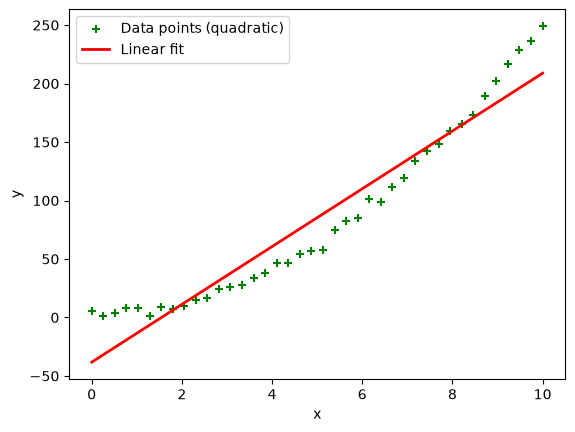

In [47]:
np.random.seed(0)
x_nl = np.linspace(0, 10, 40)
noise_nl = np.random.normal(0, 3, size=x_nl.shape)
y_nl = 2.5 * x_nl**2 + noise_nl
X_nl = x_nl.reshape(-1, 1)

lin_nl = LinearRegression()
lin_nl.fit(X_nl, y_nl)
yPredict_nl = lin_nl.predict(X_nl)

print(f"MAE = {mean_absolute_error(y_nl, yPredict_nl)}")
print(f"MSE = {mean_squared_error(y_nl, yPredict_nl)}")
print(f"R2  = {r2_score(y_nl, yPredict_nl)}")

plt.figure()
plt.scatter(x_nl, y_nl, color='green', marker='+', label='Data points (quadratic)')
plt.plot(x_nl, yPredict_nl, color='red', linewidth=2, label='Linear fit')
plt.xlabel('x'); plt.ylabel('y'); plt.legend()
plt.show()

In [52]:
scalers = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "Normalizer": Normalizer(),
    "No scaling": None,
}

for name, sc in scalers.items():
    if sc is None:
        Xt_, Xv_ = X_t, X_val
    else:
        Xt_ = sc.fit_transform(X_t)
        Xv_ = sc.transform(X_val)

    m = MLPClassifier(hidden_layer_sizes=(50,), max_iter=300, random_state=0)
    m.fit(Xt_, y_t)
    print(f"{name:15s} accuracy = {m.score(Xv_, y_val)}")

StandardScaler  accuracy = 0.9777777777777777


/home/dan/code/ai_and_machine_lurning/undervisning/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


MinMaxScaler    accuracy = 0.975


/home/dan/code/ai_and_machine_lurning/undervisning/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Normalizer      accuracy = 0.9694444444444444
No scaling      accuracy = 0.975


KNN accuracy: 0.9694444444444444
MLP accuracy: 0.9777777777777777


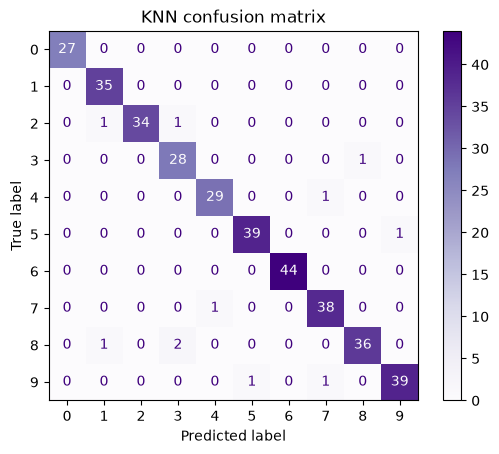

In [51]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_t_sc, y_t)
knn_acc = knn.score(X_val_sc, y_val)
print(f"KNN accuracy: {knn_acc}")
print(f"MLP accuracy: {acc}")

y_val_p_knn = knn.predict(X_val_sc)
cm_knn = confusion_matrix(y_val, y_val_p_knn)
disp_knn = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=data.target_names)
disp_knn.plot(cmap='Purples')
plt.title("KNN confusion matrix")
plt.show()